<div style="width: 100%; clear: both;">
<div style="float: left; width: 30%;">
<img src="https://upload.wikimedia.org/wikipedia/commons/f/f7/Universidad_T%C3%A9cnica_Patricular_de_Loja.png" align="left" width="80">
</div>
<div style="float: right; width: 40%;">
<p style="margin: 0; padding-top: 22px; text-align:right; color:#003366; font-size:16px"><u>Análisis de Datos y Visualización (CICO2000)</u></p>
<p style="margin: 0; text-align:right; color:#999999; font-size:15px">Ingeniería en Redes y Analítica de Datos</p>
</div>
</div>
<div style="width:100%; clear: both;">&nbsp;</div>

# Notebook 2.3 · EDA univariante
**Semana 5 · Unidad 2 · Apartados 2.4 y 2.5**

> *¿Podría un malware pasar desapercibido si no se examinan con detalle variables como la frecuencia de conexiones, los puertos utilizados o los picos inusuales de tráfico?*

El **análisis exploratorio de datos (EDA)** es la primera etapa analítica con un dataset: permite comprender su estructura, detectar problemas de calidad y orientar las decisiones posteriores. En este notebook recorrerá la primera etapa del EDA: carga, revisión general y **análisis univariante**, es decir, el estudio de **cada variable por separado**.

**Objetivos**
1. Aplicar una ruta ordenada y reproducible de EDA.
2. Clasificar las variables según su tipo para elegir las técnicas adecuadas.
3. Calcular e interpretar medidas descriptivas: media, mediana, desviación estándar, rango, cuartiles, asimetría y curtosis.
4. Elegir y construir gráficos univariantes con **matplotlib** y **seaborn**.
5. Detectar problemas en variables individuales: faltantes, valores atípicos y valores imposibles.
6. Documentar los hallazgos y las decisiones que se derivan de ellos.

## Ruta del EDA

| Paso | Tarea | Sección de este notebook |
|---|---|---|
| 1 | Cargar el dataset | 1 |
| 2 | Revisar la estructura general | 2 |
| 3 | Identificar los tipos de datos y de variables | 3 |
| 4 | Resumir con métricas descriptivas | 4 · univariante **no gráfico** |
| 5 | Elegir visualizaciones según el tipo de variable | 5 · univariante **gráfico** |
| 6 | Revisar problemas en variables individuales | 6 |
| 7 | Análisis multivariante, limpieza y transformación | Próximas semanas |

Al final, la sección 7 reúne todo en una **función reutilizable**, la sección 8 documenta los hallazgos y la sección 9 contiene los ejercicios.

**Técnicas según su enfoque y alcance**

| | No gráfica | Gráfica |
|---|---|---|
| **Univariante** (esta semana) | Estadística descriptiva de una variable | Histograma, boxplot, barras, pastel, dot plot |
| **Multivariante** (próximas semanas) | Correlación, tablas cruzadas | Dispersión, mapas de calor |

## 0. Preparación
Además de pandas y NumPy, usaremos dos librerías de visualización:
- **matplotlib**: la base de los gráficos en Python; permite controlar cada detalle.
- **seaborn**: construida sobre matplotlib; produce gráficos estadísticos con menos código y mejor estilo por defecto.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")          # estilo general de los gráficos
pd.set_option("display.precision", 3)     # mostrar 3 decimales en las tablas

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.1.1 | seaborn 0.13.2


Usaremos el dataset de la semana pasada, **Optical Interconnection Network** (UCI Machine Learning Repository, CC BY 4.0): 640 simulaciones de una red de interconexión óptica con distintas configuraciones de nodos, hilos, patrones de tráfico y carga.

En **Colab**, suba `OIN.csv` antes de continuar (ícono de carpeta 📁 o la celda siguiente).

In [2]:
# Solo en Google Colab: descomente las dos líneas para subir OIN.csv
# from google.colab import files
# files.upload()

RUTA = "OIN.csv"

## 1. Paso 1 · Cargar el dataset
Reutilizamos la función creada en el Notebook 2.1. Recuerde que este archivo usa `;` como separador y `,` como separador decimal, y tiene columnas vacías al final.

In [3]:
NOMBRES = {
    "Node Number": "nodos", "Thread Number": "hilos",
    "Spatial Distribution": "dist_espacial", "Temporal Distribution": "dist_temporal",
    "T/R": "t_r", "Processor Utilization": "util_procesador",
    "Channel Waiting Time": "espera_canal", "Input Waiting Time": "espera_entrada",
    "Network Response Time": "tiempo_respuesta", "Channel Utilization": "util_canal",
}

def cargar_oin(ruta):
    """Carga OIN.csv y devuelve un DataFrame con nombres de columnas cortos."""
    datos = pd.read_csv(ruta, sep=";", decimal=",")
    datos = datos.dropna(axis=1, how="all")           # columnas vacías
    datos.columns = datos.columns.str.strip()         # espacios en los nombres
    return datos.rename(columns=NOMBRES)

df = cargar_oin(RUTA)
df.head()

,nodos,hilos,dist_espacial,dist_temporal,t_r,util_procesador,espera_canal,espera_entrada,tiempo_respuesta,util_canal
0,64,4,UN,Client-Server,0.1,0.840,1.975,308.492,700.514,0.352
1,64,4,UN,Client-Server,0.2,0.827,9.556,291.038,864.599,0.506
2,64,4,UN,Client-Server,0.3,0.803,27.028,264.928,839.373,0.639
3,64,4,UN,Client-Server,0.4,0.723,61.849,235.777,1256.053,0.767
4,64,4,UN,Client-Server,0.5,0.721,121.086,189.680,1343.876,0.808


### ¿Se cargaron todas las filas?
Se recomienda comparar el tamaño de la **fuente** con el del **DataFrame**. Contamos las líneas del archivo (menos el encabezado) y las comparamos con las filas cargadas.

In [4]:
with open(RUTA, encoding="utf-8") as f:
    lineas_archivo = sum(1 for linea in f if linea.strip())   # líneas no vacías

print("Filas en el archivo (sin encabezado):", lineas_archivo - 1)
print("Filas en el DataFrame:               ", len(df))
print("¿Coinciden?", lineas_archivo - 1 == len(df))

Filas en el archivo (sin encabezado): 640
Filas en el DataFrame:                640
¿Coinciden? True


## 2. Paso 2 · Estructura general
Puntos de control de la revisión inicial: número de filas y columnas, nombres de atributos, tipos de datos, valores faltantes y duplicados.

In [5]:
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
print("Columnas:", df.columns.tolist())

Filas: 640 | Columnas: 10
Columnas: ['nodos', 'hilos', 'dist_espacial', 'dist_temporal', 't_r', 'util_procesador', 'espera_canal', 'espera_entrada', 'tiempo_respuesta', 'util_canal']


In [6]:
df.info() # presentar estructura

<class 'pandas.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   nodos             640 non-null    int64  
 1   hilos             640 non-null    int64  
 2   dist_espacial     640 non-null    str    
 3   dist_temporal     640 non-null    str    
 4   t_r               640 non-null    float64
 5   util_procesador   640 non-null    float64
 6   espera_canal      640 non-null    float64
 7   espera_entrada    640 non-null    float64
 8   tiempo_respuesta  640 non-null    float64
 9   util_canal        640 non-null    float64
dtypes: float64(6), int64(2), str(2)
memory usage: 50.1 KB


In [7]:
print("Valores faltantes en total:", df.isna().sum().sum())
print("Filas duplicadas:          ", df.duplicated().sum())

Valores faltantes en total: 0
Filas duplicadas:           0


In [8]:
df.sample(5, random_state=1) # muestra aleatoria de datos

,nodos,hilos,dist_espacial,dist_temporal,t_r,util_procesador,espera_canal,espera_entrada,tiempo_respuesta,util_canal
132,64,6,PS,Client-Server,0.3,0.898,34.584,421.810,1270.946,0.713
622,16,8,PS,Asynchronous,0.3,0.966,37.242,564.654,387.492,0.808
525,16,4,HR,Asynchronous,0.6,0.448,158.804,225.489,808.222,0.710
289,64,4,PS,Asynchronous,1.0,0.397,452.322,76.947,1050.178,0.872
82,64,4,BR,Client-Server,0.3,0.884,27.691,257.635,525.911,0.549


**Primeras observaciones:** 640 filas y 10 columnas; no hay valores faltantes ni filas duplicadas; dos columnas son de texto y ocho son numéricas. Que no haya nulos **no significa** que los datos estén libres de problemas: lo comprobaremos en el paso 6.

## 3. Paso 3 · Tipos de datos y tipos de variables
Hay que distinguir dos ideas:
- **Tipo de dato** (`dtype`): cómo lo almacena Python (`int64`, `float64`, `object`/`str`).
- **Tipo de variable**: qué representa, desde el punto de vista estadístico. De esto depende qué técnica aplicar.

| Tipo de variable | Descripción | Variables en OIN | Medidas | Gráficos |
|---|---|---|---|---|
| Numérica continua | Puede tomar cualquier valor en un intervalo | `util_procesador`, `espera_canal`, `espera_entrada`, `tiempo_respuesta`, `util_canal` | Media, mediana, desviación, cuartiles, asimetría, curtosis | Histograma, boxplot |
| Numérica discreta | Valores contables, pocos valores posibles | `nodos` (16, 64), `hilos` (4–10), `t_r` (0.1–1.0 en pasos de 0.1) | Frecuencias, moda, mediana | Barras, boxplot |
| Categórica nominal | Categorías sin orden | `dist_espacial`, `dist_temporal` | Frecuencias, moda | Barras, pastel |

In [9]:
# Comprobamos cuántos valores distintos tiene cada columna: ayuda a clasificarlas
df.nunique().sort_values()

nodos                 2
dist_temporal         2
hilos                 4
dist_espacial         4
t_r                  10
util_procesador     624
util_canal          627
espera_canal        640
espera_entrada      640
tiempo_respuesta    640
dtype: int64

> ⚠️ **Ponga atención:** `t_r` es `float64`, pero solo tiene 10 valores posibles fijados por el diseño de la simulación. Por eso conviene tratarla como **discreta**. El `dtype` orienta, pero la clasificación final requiere **entender qué significa la variable**.

In [10]:
# Listas de variables por tipo: las usaremos en todo el notebook
continuas  = ["util_procesador", "espera_canal", "espera_entrada", "tiempo_respuesta", "util_canal"]
discretas  = ["nodos", "hilos", "t_r"]
categoricas = ["dist_espacial", "dist_temporal"]

# Convertir las categóricas al tipo 'category' de pandas: ocupa menos memoria y deja claro su rol
df[categoricas] = df[categoricas].astype("category")
df.dtypes

nodos                  int64
hilos                  int64
dist_espacial       category
dist_temporal       category
t_r                  float64
util_procesador      float64
espera_canal         float64
espera_entrada       float64
tiempo_respuesta     float64
util_canal           float64
dtype: object

> ⚠️ **Ponga atención:** si una columna que debería ser numérica o de fecha aparece como texto, sospeche de un problema de **carga** (por ejemplo, el separador decimal) o de **calidad** (valores como `"N/A"` o `"-"` mezclados con números). Recuerde lo que ocurrió en el Notebook 2.1 al cargar sin `decimal=","`.

## 4. Paso 4 · Univariante no gráfico: medidas descriptivas
### 4.1 Una variable numérica, paso a paso: `tiempo_respuesta`
Calculamos cada medida y la interpretamos.

In [11]:
x = df["tiempo_respuesta"]

# Tendencia central
media   = x.mean()
mediana = x.median()

# Dispersión
desv    = x.std()                    # desviación estándar (muestral)
rango   = x.max() - x.min()

# Forma de la distribución
asimetria = x.skew()
curtosis  = x.kurt()                 # pandas calcula la curtosis en EXCESO (normal = 0)

print(f"Media:       {media:10.2f}")
print(f"Mediana:     {mediana:10.2f}")
print(f"Desv. est.:  {desv:10.2f}")
print(f"Mínimo:      {x.min():10.2f} | Máximo: {x.max():.2f} | Rango: {rango:.2f}")
print(f"Asimetría:   {asimetria:10.3f}")
print(f"Curtosis:    {curtosis:10.3f}")

Media:          1504.25
Mediana:        1232.15
Desv. est.:     1202.61
Mínimo:            0.53 | Máximo: 6065.74 | Rango: 6065.21
Asimetría:        1.137
Curtosis:         1.039


**Interpretación**
- La **media (≈1504) es mayor que la mediana (≈1232)**: algunos valores muy altos "arrastran" la media hacia arriba. La mediana es más representativa del valor típico.
- La **asimetría positiva (≈1.1)** indica una cola larga hacia los valores altos: pocas configuraciones tienen tiempos de respuesta mucho mayores que el resto.
- La **curtosis positiva (≈1.0)** indica colas algo más pesadas que una distribución normal: hay más valores extremos de lo esperado.
- El **mínimo (0.53)** es sospechoso: un tiempo de respuesta casi nulo no es coherente con el resto de valores. Lo investigaremos en el paso 6.

**Guía rápida para interpretar la forma**

| Medida | Valor | Interpretación |
|---|---|---|
| Asimetría | ≈ 0 (entre −0.5 y 0.5) | Aproximadamente simétrica |
| | > 0 | Sesgo a la derecha: cola hacia valores altos (media > mediana) |
| | < 0 | Sesgo a la izquierda: cola hacia valores bajos (media < mediana) |
| Curtosis (exceso) | ≈ 0 | Colas similares a una normal |
| | > 0 | Colas pesadas: más valores extremos |
| | < 0 | Colas ligeras: distribución más "plana" |

> ⚠️ **Ponga atención:** estos umbrales son orientativos. La forma de una distribución se interpreta **junto con un gráfico**, nunca solo con un número.

In [12]:
# Percentiles: dividen la distribución en 100 partes. Útiles para fijar umbrales (p. ej., SLA de respuesta)
x.quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).round(1)

0.05     113.1
0.10     212.3
0.25     580.7
0.50    1232.2
0.75    2115.3
0.90    3300.1
0.95    3922.6
Name: tiempo_respuesta, dtype: float64

Por ejemplo, el percentil 90 indica que el 90 % de las configuraciones tiene un tiempo de respuesta menor o igual a ese valor. En redes, los percentiles altos (p90, p95, p99) se usan para definir umbrales de calidad de servicio, porque describen la experiencia en los peores casos mejor que el promedio.

### 4.2 Analizar todas las variables numéricas

In [13]:
df[continuas].describe().T

,count,mean,std,min,25%,50%,75%,max
util_procesador,640.0,0.649,0.195,0.202,0.493,0.625,0.833,0.987
espera_canal,640.0,377.459,381.975,0.951,29.248,265.615,664.965,1627.330
espera_entrada,640.0,333.247,233.722,33.036,137.731,261.856,485.944,892.852
tiempo_respuesta,640.0,1504.248,1202.607,0.529,580.676,1232.150,2115.327,6065.737
util_canal,640.0,26.348,223.782,0.137,0.588,0.774,0.906,2895.323


In [14]:
def resumen_numerico(datos, columnas):
    """Tabla con medidas de centralidad, dispersión y forma para varias columnas numéricas."""
    filas = []
    for c in columnas:
        s = datos[c]
        filas.append({
            "variable": c, "rango": s.max() - s.min(),
            "mediana": s.median(),
            "asimetria": s.skew(), "curtosis": s.kurt(),
        })
    return pd.DataFrame(filas).set_index("variable")

resumen = resumen_numerico(df, continuas)
resumen.round(3)

,rango,mediana,asimetria,curtosis
variable,,,,
util_procesador,0.784,0.625,0.046,-1.135
espera_canal,1626.380,265.615,0.771,-0.591
espera_entrada,859.816,261.856,0.783,-0.577
tiempo_respuesta,6065.207,1232.150,1.137,1.039
util_canal,2895.186,0.774,9.872,104.520


**¿Qué llama la atención?**
- `util_procesador` es casi simétrica (asimetría ≈ 0) y "plana" (curtosis negativa): sus valores se reparten de forma bastante uniforme.
- `espera_canal` y `espera_entrada` tienen asimetría positiva moderada.
- **`util_canal` tiene asimetría ≈ 9.9 y curtosis ≈ 104**, valores extremadamente altos. Además, su máximo es 2895 cuando una **utilización** debería estar entre 0 y 1. Esto no es una característica de la red: es una **señal de alerta de calidad de datos**, que examinaremos en el paso 6.

### 4.3 Variables categóricas y discretas: frecuencias y moda
Estas variables se resumen con **frecuencias** (absolutas y relativas) y con la **moda** (valor más frecuente).

In [30]:
"""Frecuencia absoluta, relativa (%) y acumulada de una variable categórica o discreta."""
serie = df["dist_espacial"] # Como ejemplo se ilustra la variable "dist_espacial"
t = serie.value_counts(sort=False).to_frame("frecuencia")
t["porcentaje"] = (t["frecuencia"] / t["frecuencia"].sum() * 100).round(1)
t

,frecuencia,porcentaje
dist_espacial,,
BR,160,25.0
HR,160,25.0
PS,160,25.0
UN,160,25.0


In [31]:
serie.mode().tolist()

['BR', 'HR', 'PS', 'UN']

**Interpretación:** la variable categoría ```dist_espacial``` tiene exactamente la misma frecuencia (160 filas por cada patrón espacial), así que **no hay una moda única**: pandas devuelve todos los valores. Esto ocurre porque el dataset proviene de un **experimento balanceado**, en el que cada combinación de factores se simuló el mismo número de veces.

> ⚠️ **Ponga atención:** en datos reales (por ejemplo, registros de tráfico) lo habitual es que las frecuencias sean **desiguales**: unos pocos protocolos o puertos concentran la mayoría de eventos. Un cambio brusco en esas frecuencias puede indicar un incidente.

## 5. Paso 5 · Univariante gráfico
Los estadísticos resumen una variable, pero los gráficos **muestran** la forma de la distribución y los valores extremos. La elección del gráfico depende del tipo de variable:

| Gráfico | ¿Cuándo usarlo? | Qué ayuda a observar | seaborn |
|---|---|---|---|
| Histograma | Numérica continua | Distribución y frecuencias | `sns.histplot` |
| Boxplot | Numérica discreta o continua | Dispersión y atípicos | `sns.boxplot` |
| Gráfico de barras | Categórica o discreta | Frecuencias de categorías | `sns.countplot` |
| Gráfico de pastel | Categórica con pocas categorías | Proporciones | `plt.pie` |
| Dot plot | Observaciones individuales | Densidad y distribución de puntos | `sns.stripplot` |

### 5.1 Histograma
Divide el rango de la variable en intervalos (*bins*) y cuenta cuántos valores caen en cada uno. A continuación se ilustra para ```tiempo_respuesta```.

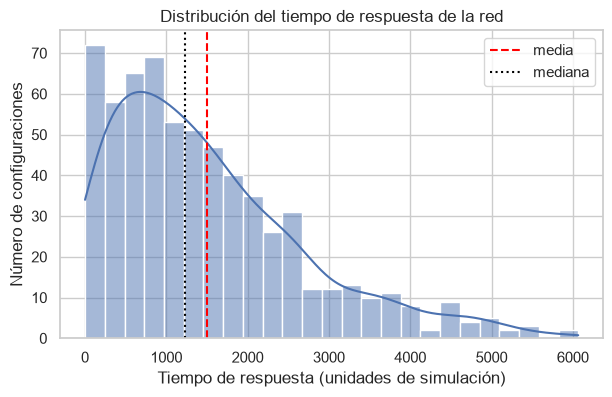

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x="tiempo_respuesta", bins=25, kde=True, ax=ax)   # kde: curva de densidad suavizada
ax.axvline(df["tiempo_respuesta"].mean(),   color="red",   ls="--", label="media")
ax.axvline(df["tiempo_respuesta"].median(), color="black", ls=":",  label="mediana")
ax.set(title="Distribución del tiempo de respuesta de la red",
       xlabel="Tiempo de respuesta (unidades de simulación)", ylabel="Número de configuraciones")
ax.legend()
plt.show()

El histograma confirma lo que indicaban la asimetría y la diferencia entre media y mediana: la mayoría de configuraciones se concentra en valores bajos y medios, con una **cola larga hacia la derecha**.

> ⚠️ **Ponga atención: el número de intervalos cambia la lectura.** Con pocos intervalos se ocultan detalles; con demasiados, el gráfico se vuelve ruidoso.

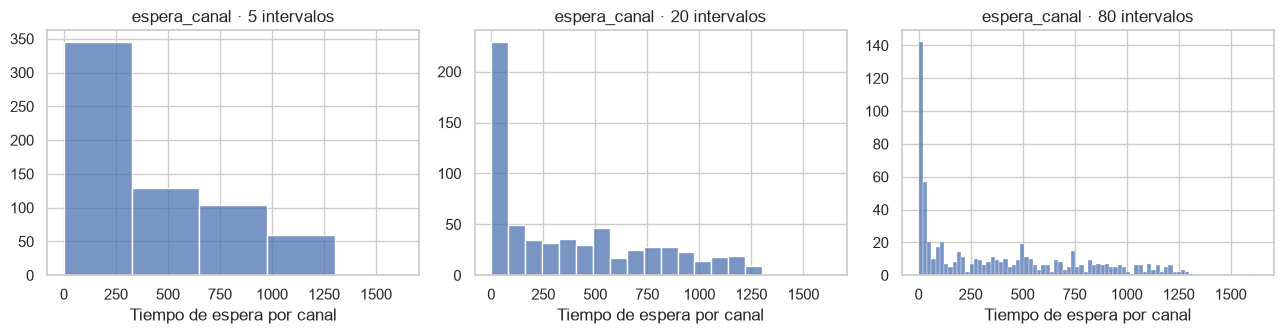

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=False)
for ax, b in zip(axes, [5, 20, 80]):
    sns.histplot(df["espera_canal"], bins=b, ax=ax)
    ax.set(title=f"espera_canal · {b} intervalos", xlabel="Tiempo de espera por canal", ylabel="")
plt.tight_layout()
plt.show()

### 5.2 Boxplot (diagrama de caja)
Resume la distribución con cinco valores y señala los posibles atípicos:

```
   o        |-------[  Q1  | mediana |  Q3  ]-------|        o   o
 atípico  bigote                                 bigote      atípicos
```
- La **caja** va de Q1 a Q3 (contiene el 50 % central de los datos); la línea interior es la **mediana**.
- Los **bigotes** llegan hasta el último valor que está dentro de **1.5 × IQR** desde la caja.
- Los **puntos** fuera de los bigotes son **candidatos a valores atípicos**.

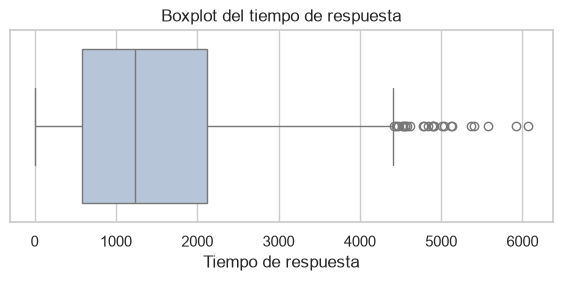

In [19]:
fig, ax = plt.subplots(figsize=(7, 2.5))
sns.boxplot(x=df["tiempo_respuesta"], color="lightsteelblue", ax=ax)
ax.set(title="Boxplot del tiempo de respuesta", xlabel="Tiempo de respuesta")
plt.show()

### 5.3 Histograma + boxplot: dos vistas de la misma variable
Combinar ambos gráficos permite ver la forma **y** los atípicos a la vez.

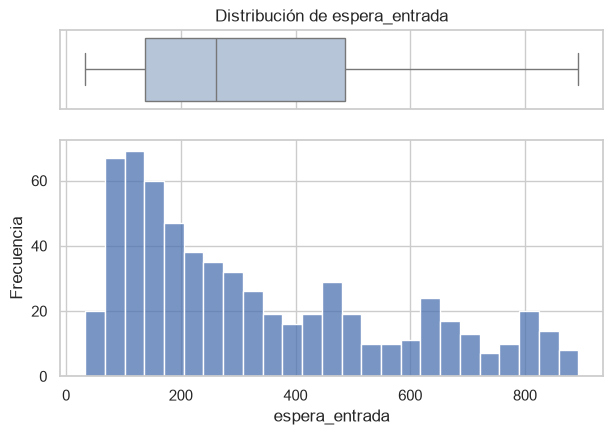

In [20]:
def hist_box(datos, columna, bins=25):
    """Dibuja un boxplot encima de un histograma para una variable numérica."""
    fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(7, 4.5), sharex=True,
                                          gridspec_kw={"height_ratios": [1, 3]})
    sns.boxplot(x=datos[columna], ax=ax_box, color="lightsteelblue")
    sns.histplot(x=datos[columna], bins=bins, ax=ax_hist)
    ax_box.set(xlabel="", title=f"Distribución de {columna}")
    ax_hist.set(ylabel="Frecuencia")
    plt.show()

hist_box(df, "espera_entrada")

### 5.4 Variables discretas: barras y boxplot
Como en la Figura 19 de la guía, una variable discreta puede representarse con un gráfico de barras (frecuencia de cada valor) y con un boxplot.

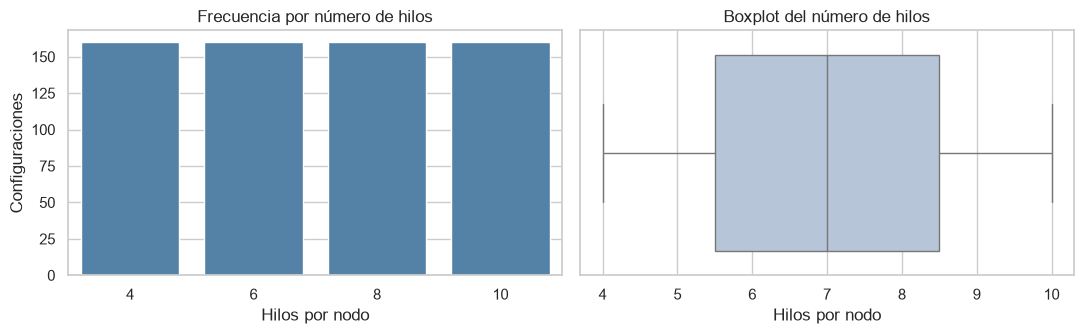

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(data=df, x="hilos", ax=axes[0], color="steelblue")
axes[0].set(title="Frecuencia por número de hilos", xlabel="Hilos por nodo", ylabel="Configuraciones")
sns.boxplot(x=df["hilos"], ax=axes[1], color="lightsteelblue")
axes[1].set(title="Boxplot del número de hilos", xlabel="Hilos por nodo")
plt.tight_layout()
plt.show()

Las barras tienen la misma altura: confirma el **diseño balanceado** del experimento. En variables de diseño como esta, el gráfico sirve para **verificar** que todas las combinaciones están presentes.

### 5.5 Variables categóricas: barras y pastel

In [23]:
df.columns

Index(['nodos', 'hilos', 'dist_espacial', 'dist_temporal', 't_r',
       'util_procesador', 'espera_canal', 'espera_entrada', 'tiempo_respuesta',
       'util_canal'],
      dtype='str')

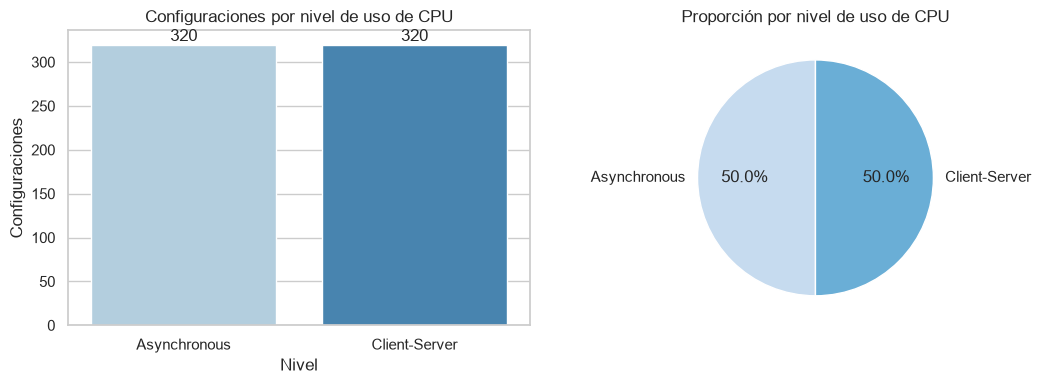

In [32]:
frec = df["dist_temporal"].value_counts(sort=False)
# diagrama de barras
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="dist_temporal", ax=axes[0], palette="Blues", hue="dist_temporal", legend=False, dodge=False)
axes[0].set(title="Configuraciones por nivel de uso de CPU", xlabel="Nivel", ylabel="Configuraciones")
for barra in axes[0].containers:                      # etiqueta con el valor sobre cada barra
    axes[0].bar_label(barra)

# diagrama de pastel
axes[1].pie(frec, labels=frec.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("Blues", 3))
axes[1].set_title("Proporción por nivel de uso de CPU")
plt.tight_layout()
plt.show()

### 5.6 Una vista general de todas las variables continuas

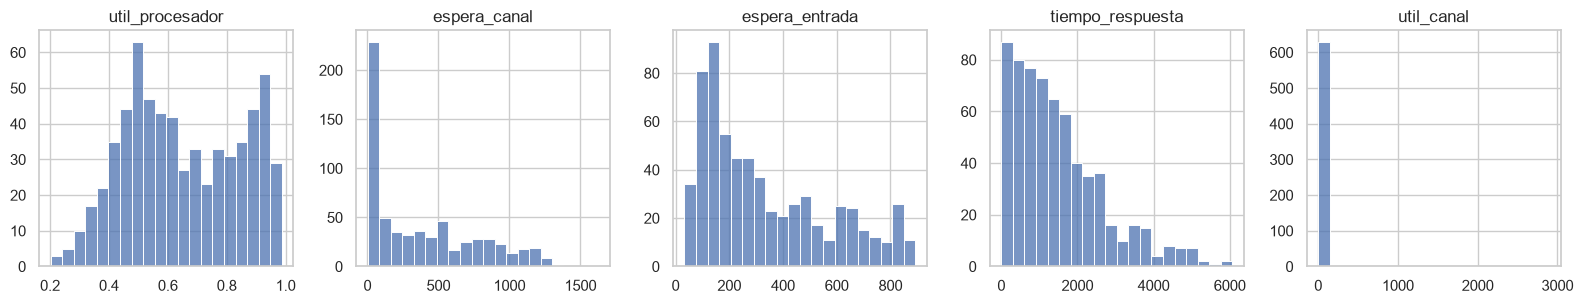

In [25]:
fig, axes = plt.subplots(1, len(continuas), figsize=(16, 3.2))
for ax, c in zip(axes, continuas):
    sns.histplot(df[c], bins=20, ax=ax)
    ax.set(title=c, xlabel="", ylabel="")
plt.tight_layout()
plt.show()

## 6. Paso 6 · Problemas en variables individuales
### 6.1 Valores faltantes

In [26]:
faltantes = pd.DataFrame({"nulos": df.isna().sum(),
                          "porcentaje": (df.isna().mean() * 100).round(2)})
faltantes

,nulos,porcentaje
nodos,0,0.0
hilos,0,0.0
dist_espacial,0,0.0
dist_temporal,0,0.0
t_r,0,0.0
util_procesador,0,0.0
espera_canal,0,0.0
espera_entrada,0,0.0
tiempo_respuesta,0,0.0
util_canal,0,0.0


No hay valores faltantes. Si los hubiera, el EDA debería responder: ¿cuántos son?, ¿en qué variables?, ¿se concentran en ciertos grupos? La decisión (eliminar, imputar o elegir un método que los tolere) se estudiará en la unidad de preparación de datos.

### 6.2 Valores atípicos con boxplot

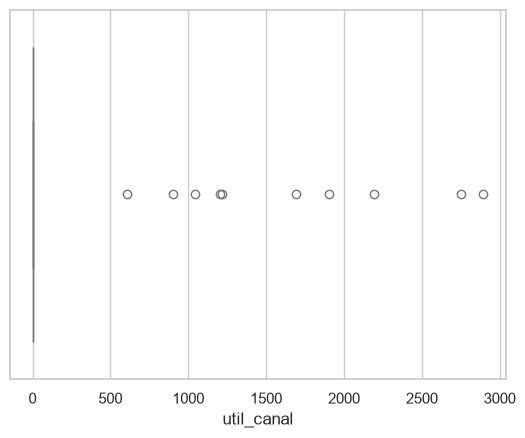

In [27]:
sns.boxplot(x=df["util_canal"],  color="lightsteelblue")
plt.show()

## 7. Una rutina reutilizable
Se recomienda usar un proceso **modular** para reutilizar funciones en otros datasets. Esta función elige automáticamente las medidas y gráficos según el tipo de la variable.

=== espera_canal | dtype: float64 | nulos: 0 | valores distintos: 640 ===
media=377.459  mediana=265.615  desv=381.975  asimetría=0.77  curtosis=-0.59


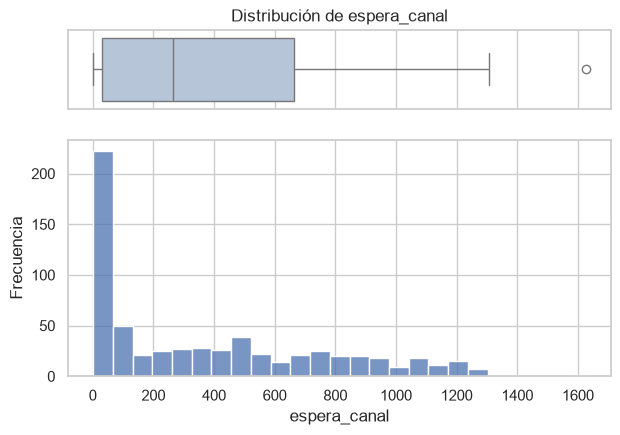

In [36]:
def eda_univariante(datos, columna, bins=25):
    """Resumen numérico y gráfico de una variable, según sea numérica o categórica."""
    s = datos[columna]
    print(f"=== {columna} | dtype: {s.dtype} | nulos: {s.isna().sum()} | valores distintos: {s.nunique()} ===")

    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 15:          # numérica continua
        print(f"media={s.mean():.3f}  mediana={s.median():.3f}  desv={s.std():.3f}  "
              f"asimetría={s.skew():.2f}  curtosis={s.kurt():.2f}")
        hist_box(datos, columna, bins)
    else:                                                               # categórica o discreta
        display(tabla_frecuencias(s))
        print("moda:", s.mode().tolist())
        fig, ax = plt.subplots(figsize=(6, 3))
        sns.countplot(x=s, ax=ax, color="steelblue")
        ax.set(title=f"Frecuencias de {columna}", ylabel="Frecuencia")
        plt.show()

eda_univariante(df, "espera_canal") # prueba con "espera_canal" - continua

=== dist_temporal | dtype: category | nulos: 0 | valores distintos: 2 ===


,frecuencia,porcentaje,pct_acumulado
dist_temporal,,,
Asynchronous,320,50.0,50.0
Client-Server,320,50.0,100.0


moda: ['Asynchronous', 'Client-Server']


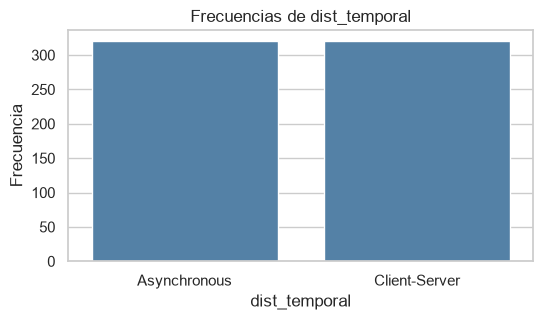

In [37]:
eda_univariante(df, "dist_temporal") # prueba con variable categórica

## 8. Documentar hallazgos y decisiones
El EDA no termina con los gráficos: hay que **registrar** lo encontrado y la decisión que se deriva, para que el análisis sea trazable y otras personas (o usted mismo más adelante) entiendan por qué se tomó cada decisión.

In [38]:
hallazgos = pd.DataFrame([
    {"variable": "todas", "hallazgo": "640 filas, 10 columnas, sin nulos ni duplicados",
     "evidencia": "info(), isna(), duplicated()", "decision": "Ninguna acción"},
    {"variable": "dist_espacial, dist_temporal, nodos, hilos, t_r", "hallazgo": "Frecuencias idénticas: diseño balanceado",
     "evidencia": "tabla_frecuencias(), countplot", "decision": "Tratar como factores del experimento"},
    {"variable": "tiempo_respuesta", "hallazgo": "Sesgo a la derecha; 24 atípicos con carga alta (t_r ≥ 0.7)",
     "evidencia": "asimetría 1.1, boxplot, regla IQR", "decision": "Conservar: congestión real; evaluar transformación"},
    {"variable": "util_canal, tiempo_respuesta", "hallazgo": "10 filas (64 nodos, 4 hilos, PS) con valores intercambiados",
     "evidencia": "util_canal > 1, tiempo_respuesta < 1, regla de dominio", "decision": "Corregir en la etapa de limpieza; consultar la fuente"},
])
hallazgos

,variable,hallazgo,evidencia,decision
0,todas,"640 filas, 10 columnas, sin nulos ni duplicados","info(), isna(), duplicated()",Ninguna acción
1,"dist_espacial, dist_temporal, nodos, hilos, t_r",Frecuencias idénticas: diseño balanceado,"tabla_frecuencias(), countplot",Tratar como factores del experimento
2,tiempo_respuesta,Sesgo a la derecha; 24 atípicos con carga alta...,"asimetría 1.1, boxplot, regla IQR",Conservar: congestión real; evaluar transforma...
3,"util_canal, tiempo_respuesta","10 filas (64 nodos, 4 hilos, PS) con valores i...","util_canal > 1, tiempo_respuesta < 1, regla de...",Corregir en la etapa de limpieza; consultar la...


In [39]:
hallazgos.to_csv("hallazgos_eda_univariante.csv", index=False)   # registro persistente de los hallazgos

## 9. Ejercicios
Resuelva cada ejercicio en la celda indicada. **Comente su código** y escriba la interpretación en las celdas de texto.

### Ejercicio 1 · Medidas descriptivas
Para `espera_entrada`, calcule media, mediana, desviación estándar, rango, IQR, coeficiente de variación, asimetría y curtosis.
a) ¿La distribución es simétrica o sesgada? Justifique con dos medidas.
b) ¿Qué valor representa mejor el valor típico: la media o la mediana? ¿Por qué?

In [ ]:
# Ejercicio 1

*Interpretación del ejercicio 1:*

### Ejercicio 2 · Histograma y boxplot
a) Construya un histograma de `util_procesador` con 10, 20 y 40 intervalos. ¿Cuál describe mejor la distribución?
b) Use `hist_box()` con `espera_canal` y explique qué representa el único atípico que señala el boxplot. *Pista:* revise la fila con `df.loc[mascara]`.

In [ ]:
# Ejercicio 2

### Ejercicio 3 · Variables categóricas
a) Cree la variable `nivel_espera` a partir de `espera_canal` con `pd.cut()` y tres niveles: `"baja"` (0–200), `"media"` (200–700) y `"alta"` (más de 700).
b) Obtenga su tabla de frecuencias y su moda.
c) Represéntela con un gráfico de barras y uno de pastel. ¿Cuál comunica mejor la información?

In [ ]:
# Ejercicio 3

### Ejercicio 4 · Atípicos: ¿error o evento real?
a) Elija una variable numérica y genere el boxplot para determinar si hay presencia de outliers.

In [ ]:
# Ejercicio 4

### Ejercicio 5 · Replicar la rutina en otro dataset
Cargue el archivo `datos/bm_internet.csv` que generó en el Notebook 2.2 (o cualquier otro dataset de redes o telecomunicaciones) y aplique `eda_univariante()` a una variable numérica y a una categórica. Agregue al menos dos filas a una tabla de hallazgos como la de la sección 8.

In [ ]:
# Ejercicio 5

### Reflexión
¿Por qué el análisis univariante es un paso necesario antes de estudiar relaciones entre variables? Responda con un ejemplo de este dataset.

*Su respuesta:*

## Resumen
- El EDA sigue una **ruta**: cargar → revisar la estructura → identificar tipos → resumir → visualizar → revisar problemas → documentar.
- El **tipo de variable** (continua, discreta, categórica) determina qué medidas y gráficos usar.
- **Media vs. mediana**, **asimetría** y **curtosis** describen la forma de la distribución; confírmelas siempre con un gráfico.
- **Histograma** y **boxplot** para numéricas; **barras** y **pastel** para categóricas; **dot plot** para ver observaciones individuales.
- Un **atípico** puede ser un evento real o un error: combine reglas estadísticas (IQR) con **reglas de dominio**.
- **Documente** cada hallazgo y la decisión que se deriva de él.

**Referencia del dataset:** Optical Interconnection Network. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/449/optical+interconnection+network